In [8]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [3]:
#Defining the data paths

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Files found:", [file.name for file in DATA_DIR.iterdir()])

Project directory: C:\Users\Utsab\Desktop\CineRL
Data directory: C:\Users\Utsab\Desktop\CineRL\data
Files found: ['movies.dat', 'ratings.dat', 'README', 'users.dat']


In [4]:
ratings = pd.read_csv(
    DATA_DIR / "ratings.dat",
    sep="::",
    engine="python",
    names=["user_id", "movie_id", "rating", "timestamp"],
    encoding="latin-1"
)

movies = pd.read_csv(
    DATA_DIR / "movies.dat",
    sep="::",
    engine="python",
    names=["movie_id", "title", "genres"],
    encoding="latin-1"
)

users = pd.read_csv(
    DATA_DIR / "users.dat",
    sep="::",
    engine="python",
    names=["user_id", "gender", "age", "occupation", "zip_code"],
    encoding="latin-1"
)

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [5]:
print("Ratings:", ratings.shape)
print("Movies:", movies.shape)
print("Users:", users.shape)

Ratings: (1000209, 4)
Movies: (3883, 3)
Users: (6040, 5)


In [6]:
print("Rating distribution:")
print(ratings["rating"].value_counts().sort_index())

print("\nRating statistics:")
print(ratings["rating"].describe())

print("\nUnique users:", ratings["user_id"].nunique())
print("Unique rated movies:", ratings["movie_id"].nunique())

Rating distribution:
rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64

Rating statistics:
count    1.000209e+06
mean     3.581564e+00
std      1.117102e+00
min      1.000000e+00
25%      3.000000e+00
50%      4.000000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

Unique users: 6040
Unique rated movies: 3706


,movie_count
genres,
Drama,1603
Comedy,1200
Action,503
Thriller,492
Romance,471
Horror,343
Adventure,283
Sci-Fi,276
Children's,251


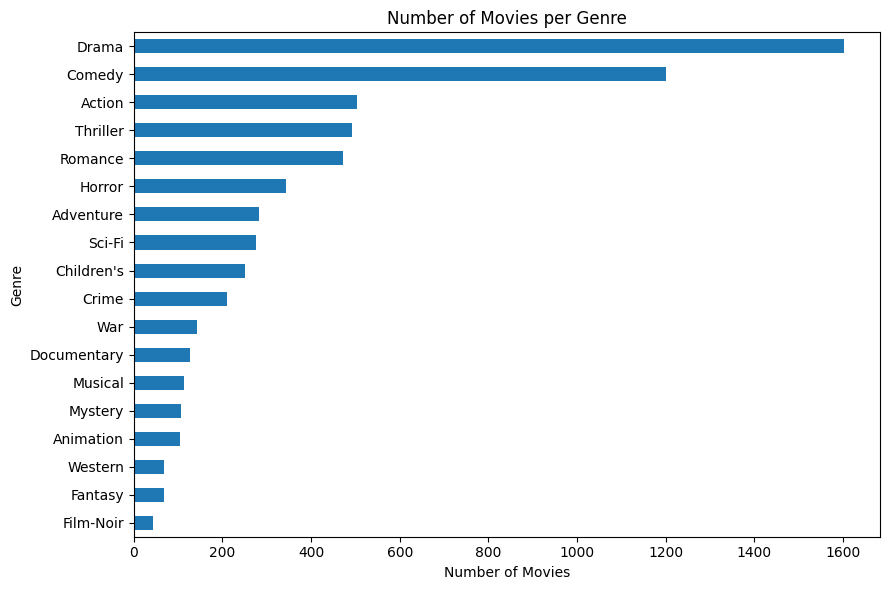

In [9]:
# Split genre strings into individual genres
genre_counts = (
    movies["genres"]
    .str.split("|")
    .explode()
    .value_counts()
)

display(genre_counts.to_frame(name="movie_count"))

# Visualize genre frequency
genre_counts.sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title="Number of Movies per Genre"
)

plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

In [10]:
# Sort each user's ratings chronologically
ratings = ratings.sort_values(
    ["user_id", "timestamp"]
).reset_index(drop=True)

# Split each user's ratings: earliest 80% for training
train_parts = []
test_parts = []

for user_id, user_ratings in ratings.groupby("user_id", sort=False):
    split_index = int(len(user_ratings) * 0.8)

    train_parts.append(user_ratings.iloc[:split_index])
    test_parts.append(user_ratings.iloc[split_index:])

train_ratings = pd.concat(train_parts).reset_index(drop=True)
test_ratings = pd.concat(test_parts).reset_index(drop=True)

print("Training ratings:", train_ratings.shape)
print("Testing ratings:", test_ratings.shape)

print("Training users:", train_ratings["user_id"].nunique())
print("Testing users:", test_ratings["user_id"].nunique())

Training ratings: (797758, 4)
Testing ratings: (202451, 4)
Training users: 6040
Testing users: 6040


In [11]:
# Create a folder for prepared datasets
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(exist_ok=True)

# Save the split datasets
train_ratings.to_csv(
    PROCESSED_DIR / "train_ratings.csv",
    index=False
)

test_ratings.to_csv(
    PROCESSED_DIR / "test_ratings.csv",
    index=False
)

# Save the movie catalog
movies.to_csv(
    PROCESSED_DIR / "movies.csv",
    index=False
)

print("Prepared datasets saved to:", PROCESSED_DIR)
print("Files:", [file.name for file in PROCESSED_DIR.iterdir()])

Prepared datasets saved to: C:\Users\Utsab\Desktop\CineRL\data\processed
Files: ['movies.csv', 'test_ratings.csv', 'train_ratings.csv']
